
*There was no change to the original BERT fine-tuning setup (April 11 experiment); the training logic and hyperparameters remain unchanged.
To ensure reproducibility, seed=42 and data_seed=42 were explicitly set in the training arguments, as transformer fine-tuning involves stochastic components such as random initialization, dropout, and data shuffling.

*This was done to ensure reproducibility of the fine-tuning experiments. Transformer training involves stochastic components such as random initialization, dropout, and data shuffling, which can lead to variations in evaluation metrics across runs. By fixing seed and data_seed, the training process becomes consistent, allowing fair comparison across models and experiments and improving the reliability of reported results.

*It removed run-to-run variability and ensured that all reported improvements are due to model or data changes, not randomness.




** chinese datatset 4 laass here max length is 128

In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# ── Config ───────────────────────────────────────────────────
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
#DATA_PATH = "/content/drive/MyDrive/conversation_cn.json"
RESULTS_DIR = "/content/drive/MyDrive/thesis_final_results_4class_noaugment"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
#VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]
VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]

#label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3, "Inquire": 4}
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20

print("Config loaded.")
print("label2id:", label2id)
print("Using original JSON only for splits and context.")

Config loaded.
label2id: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
Using original JSON only for splits and context.


In [5]:
# ── Load original JSON and create full-turn + target-turn dataframes ──────
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

for col in ["conversation_id", "role", "text"]:
    df_turns_full[col] = df_turns_full[col].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("")

# Only labeled user turns are prediction targets
target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

# Full conversation lookup for context reconstruction
turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Full turn rows (all roles):", len(df_turns_full))
print("Target user-turn rows:", len(target_df))
print("Unique conversations:", df_turns_full["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Full turn rows (all roles): 5633
Target user-turn rows: 3179
Unique conversations: 826
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
from sklearn.model_selection import GroupShuffleSplit

# Step 1: Train+Val vs Test
gss1 = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

# Step 2: Train vs Val
gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

Train: 2014
Val  : 503
Test : 662


In [7]:
# ── Context builder ────────────────────────────────────────────
def build_context_dataset(df_split, turns_by_conv):
    """
    Build one input per labeled user turn.
    Context = all previous turns in the same conversation (user + system)
    + current user turn.
    """
    X, y = [], []

    for _, row in df_split.iterrows():
        cid = row["conversation_id"]
        ti = int(row["turn_index"])

        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()

        if history:
            full_text = "\n".join(history) + "\n" + f"USER: {current_turn}"
        else:
            full_text = f"USER: {current_turn}"

        X.append(full_text)
        y.append(row["intent"])

    return np.array(X), np.array(y)


X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train size:", len(X_train))
print("Context-aware val size  :", len(X_val))
print("Context-aware test size :", len(X_test))

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train size: 2014
Context-aware val size  : 503
Context-aware test size : 662

Train distribution:
Interpret    1130
Reveal        673
Chitchat      176
Revise         35
Name: count, dtype: int64

Val distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [8]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [9]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [10]:
# ── Encode labels ────────────────────────────────────────────
y_train_ids = np.array([label2id[l] for l in y_train])
y_val_ids   = np.array([label2id[l] for l in y_val])
y_test_ids  = np.array([label2id[l] for l in y_test])

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist
}).fillna(0)

print("Label distribution (%):")
print(dist_df)

Label distribution (%):
            train_%     val_%    test_%
Interpret  0.561072  0.580517  0.590634
Reveal     0.334161  0.320080  0.297583
Chitchat   0.087388  0.075547  0.081571
Revise     0.017378  0.023857  0.030211


In [11]:
# ── Class weights (balanced) ─────────────────────────────────
# Compute weights only from TRAIN labels
classes = np.array(sorted(np.unique(y_train_ids)))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float)

print("Class weights:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {id2label[cls_id]}: {w:.2f}")

Class weights:
  Chitchat: 2.86
  Interpret: 0.45
  Reveal: 0.75
  Revise: 14.39


In [12]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [13]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [14]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8"
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors


print("All helpers defined.")

All helpers defined.


In [15]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=5):
    """
    1. Tokenize with the model's own tokenizer
    2. Train with WeightedTrainer using TRAIN data
    3. Select best checkpoint using VAL macro-F1
    4. Plot learning curve
    5. Evaluate on TRAIN, VAL, and TEST
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)
    set_seed(RANDOM_STATE)# Set seed to ensure reproducible training and prevent run-to-run variation

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train, y_train_ids,
        X_val, y_val_ids,
        X_test, y_test_ids
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id
    )

    short_name = model_name.split("/")[-1]

    training_args = TrainingArguments(
        output_dir=f"./{short_name}_results",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=2e-5,
        weight_decay=0.01,
        seed=RANDOM_STATE,# Set seed to ensure reproducible training and prevent run-to-run variation
        data_seed=RANDOM_STATE,# Set seed to ensure reproducible training and prevent run-to-run variation
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
    )

    trainer = WeightedTrainer(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation: checks whether rare classes are learned at all
    evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation: checkpoint selection / tuning view
    evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    return trainer


print("run_model() defined.")

run_model() defined.


## DistilBERT


  MODEL: distilbert-base-uncased


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


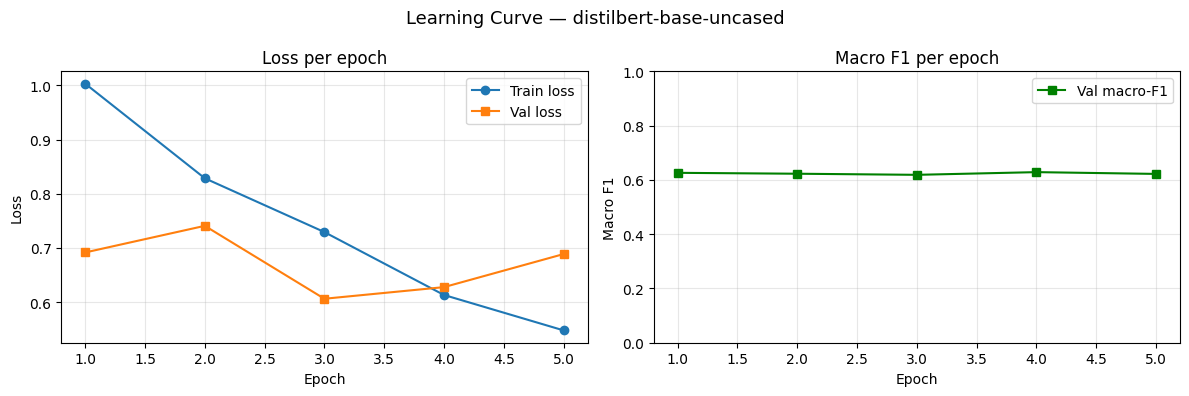

Saved: distilbert-base-uncased_learning_curve.png



=== distilbert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.827     0.790     0.808       176
   Interpret      0.959     0.981     0.970      1130
      Reveal      0.945     0.966     0.955       673
      Revise      1.000     0.086     0.158        35

    accuracy                          0.943      2014
   macro avg      0.933     0.705     0.723      2014
weighted avg      0.944     0.943     0.937      2014


=== distilbert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             139              18           19            0
true_Interpret             13            1108            9            0
true_Reveal                14               9          650            0
true_Revise                 2              20           10            3


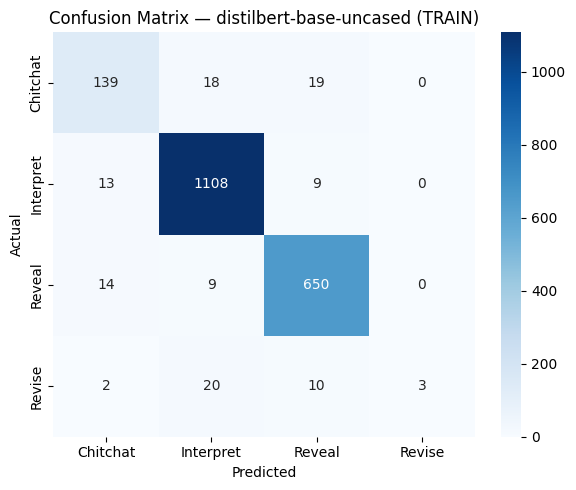


=== distilbert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.659     0.763     0.707        38
   Interpret      0.908     0.914     0.911       292
      Reveal      0.885     0.907     0.896       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.879       503
   macro avg      0.613     0.646     0.629       503
weighted avg      0.860     0.879     0.869       503


=== distilbert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              29               7            2            0
true_Interpret             13             267           12            0
true_Reveal                 2              13          146            0
true_Revise                 0               7            5            0


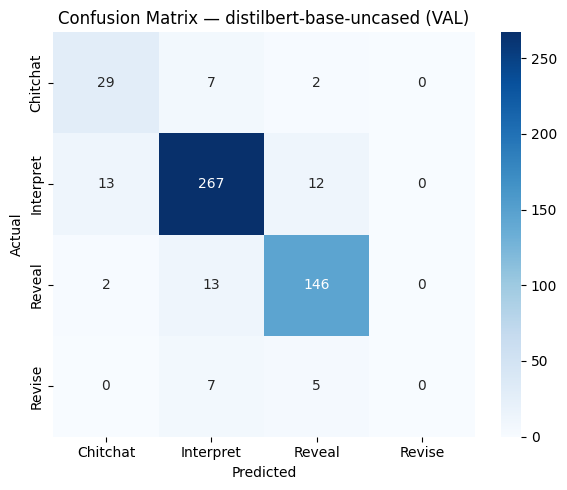


=== distilbert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Chitchat,13
1,Reveal,Interpret,13
2,Interpret,Reveal,12
3,Chitchat,Interpret,7
4,Revise,Interpret,7
5,Revise,Reveal,5
6,Chitchat,Reveal,2
7,Reveal,Chitchat,2



=== distilbert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Chitchat
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
18,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
19,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Chitchat
40,USER: hi!,Interpret,Chitchat
70,"USER: I want a foot warmer. You know, it's ver...",Interpret,Reveal
76,USER: I want a quilt\nSYSTEM: How about the du...,Interpret,Chitchat



=== distilbert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.725     0.685     0.705        54
   Interpret      0.899     0.934     0.916       391
      Reveal      0.829     0.863     0.846       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.864       662
   macro avg      0.613     0.620     0.617       662
weighted avg      0.837     0.864     0.850       662


=== distilbert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              37               8            9            0
true_Interpret              5             365           21            0
true_Reveal                 7              20          170            0
true_Revise                 2              13            5            0


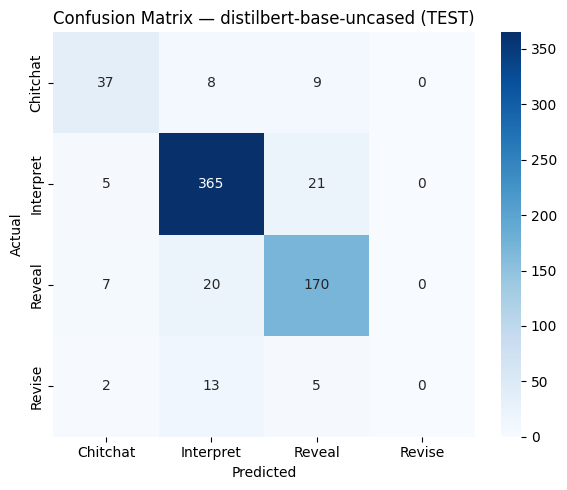


=== distilbert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,21
1,Reveal,Interpret,20
2,Revise,Interpret,13
3,Chitchat,Reveal,9
4,Chitchat,Interpret,8
5,Reveal,Chitchat,7
6,Interpret,Chitchat,5
7,Revise,Reveal,5
8,Revise,Chitchat,2



=== distilbert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Reveal
33,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Reveal
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret


In [16]:
distilbert_trainer = run_model("distilbert-base-uncased", num_epochs=5)

## RoBERTa-base


  MODEL: roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

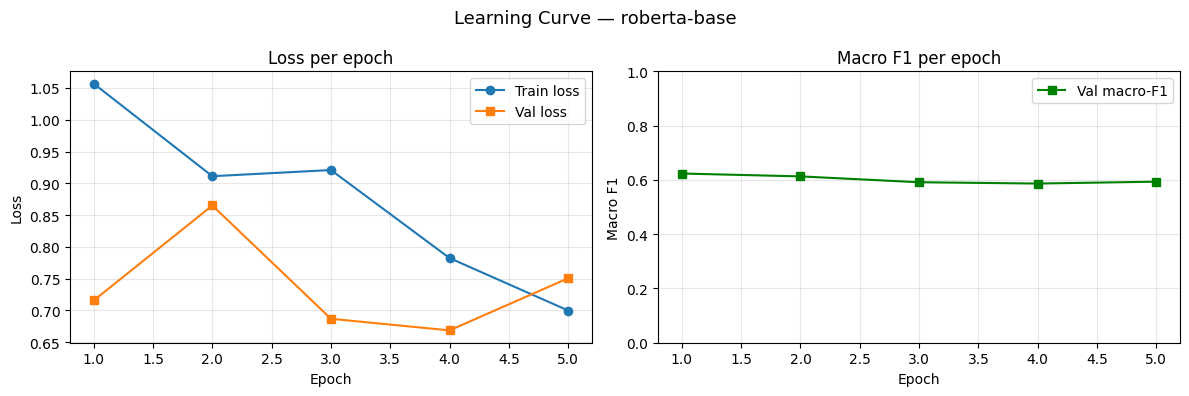

Saved: roberta-base_learning_curve.png



=== roberta-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.844     0.432     0.571       176
   Interpret      0.810     0.964     0.880      1130
      Reveal      0.900     0.774     0.832       673
      Revise      0.000     0.000     0.000        35

    accuracy                          0.837      2014
   macro avg      0.638     0.542     0.571      2014
weighted avg      0.829     0.837     0.822      2014


=== roberta-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              76              83           17            0
true_Interpret              4            1089           37            0
true_Reveal                10             142          521            0
true_Revise                 0              31            4            0


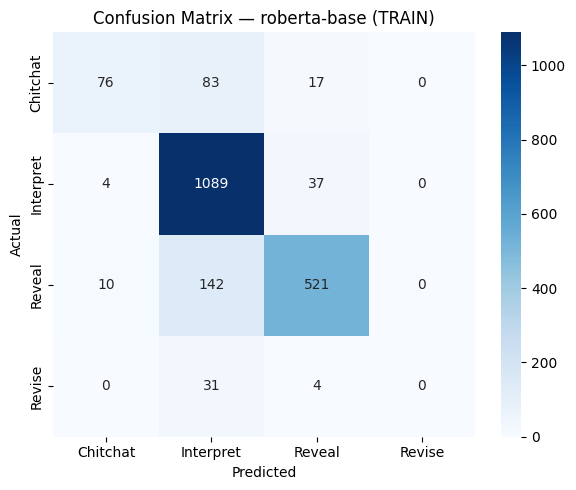


=== roberta-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.958     0.605     0.742        38
   Interpret      0.842     0.966     0.900       292
      Reveal      0.903     0.807     0.852       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.865       503
   macro avg      0.676     0.595     0.623       503
weighted avg      0.850     0.865     0.851       503


=== roberta-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              23              12            3            0
true_Interpret              1             282            9            0
true_Reveal                 0              31          130            0
true_Revise                 0              10            2            0


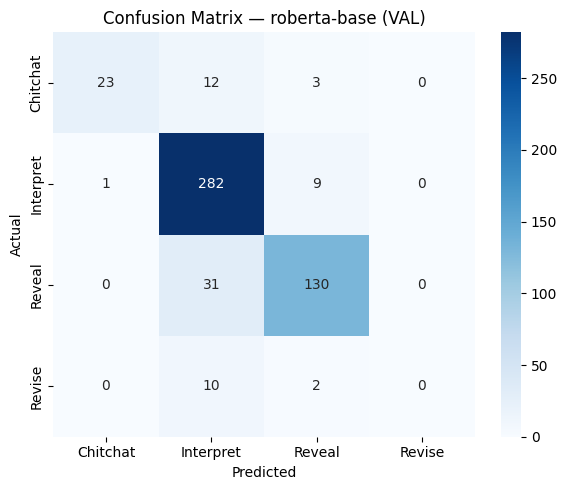


=== roberta-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,31
1,Chitchat,Interpret,12
2,Revise,Interpret,10
3,Interpret,Reveal,9
4,Chitchat,Reveal,3
5,Revise,Reveal,2
6,Interpret,Chitchat,1



=== roberta-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat
54,"USER: Hello, I would like a stereo\nSYSTEM: Pr...",Interpret,Reveal



=== roberta-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.946     0.648     0.769        54
   Interpret      0.845     0.980     0.908       391
      Reveal      0.878     0.766     0.818       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.860       662
   macro avg      0.667     0.599     0.624       662
weighted avg      0.838     0.860     0.842       662


=== roberta-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              35              12            7            0
true_Interpret              0             383            8            0
true_Reveal                 2              44          151            0
true_Revise                 0              14            6            0


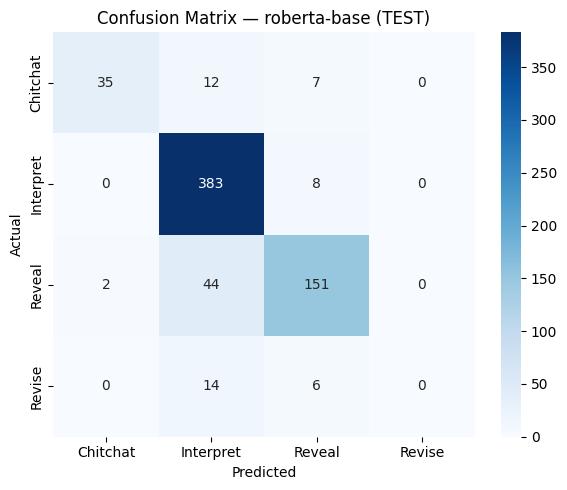


=== roberta-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,44
1,Revise,Interpret,14
2,Chitchat,Interpret,12
3,Interpret,Reveal,8
4,Chitchat,Reveal,7
5,Revise,Reveal,6
6,Reveal,Chitchat,2



=== roberta-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret


In [17]:
roberta_trainer = run_model("roberta-base", num_epochs=5)

## BERT-base-uncased


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

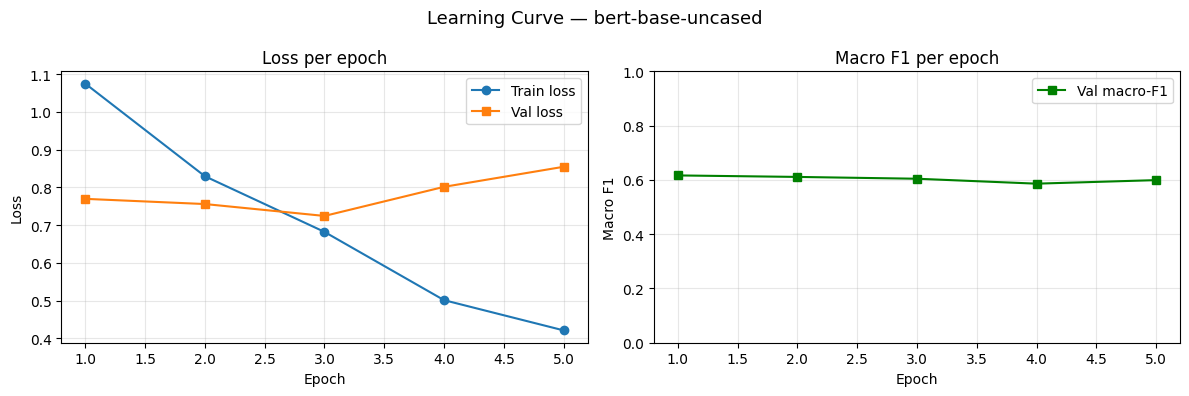

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.865     0.438     0.581       176
   Interpret      0.837     0.969     0.898      1130
      Reveal      0.901     0.826     0.862       673
      Revise      0.000     0.000     0.000        35

    accuracy                          0.858      2014
   macro avg      0.651     0.558     0.585      2014
weighted avg      0.846     0.858     0.843      2014


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              77              76           23            0
true_Interpret              3            1095           32            0
true_Reveal                 9             108          556            0
true_Revise                 0              29            6            0


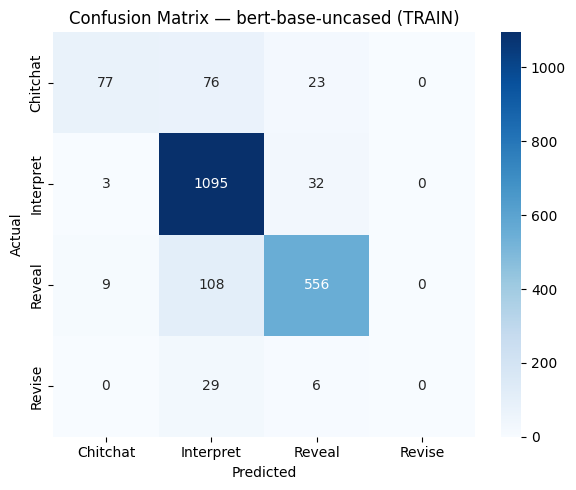


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.958     0.605     0.742        38
   Interpret      0.848     0.938     0.891       292
      Reveal      0.846     0.820     0.833       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.853       503
   macro avg      0.663     0.591     0.616       503
weighted avg      0.836     0.853     0.840       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              23              11            4            0
true_Interpret              1             274           17            0
true_Reveal                 0              29          132            0
true_Revise                 0               9            3            0


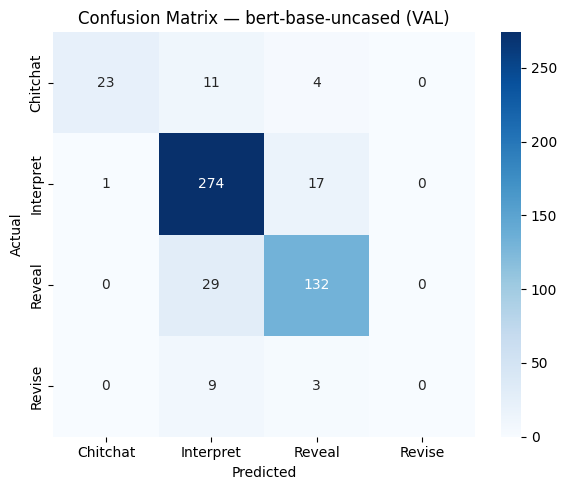


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,29
1,Interpret,Reveal,17
2,Chitchat,Interpret,11
3,Revise,Interpret,9
4,Chitchat,Reveal,4
5,Revise,Reveal,3
6,Interpret,Chitchat,1



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
2,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
21,"USER: hi,I want a phone\nSYSTEM: What size of ...",Interpret,Reveal
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.944     0.630     0.756        54
   Interpret      0.854     0.969     0.908       391
      Reveal      0.852     0.787     0.818       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.858       662
   macro avg      0.662     0.596     0.620       662
weighted avg      0.835     0.858     0.841       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              34              12            8            0
true_Interpret              0             379           12            0
true_Reveal                 2              40          155            0
true_Revise                 0              13            7            0


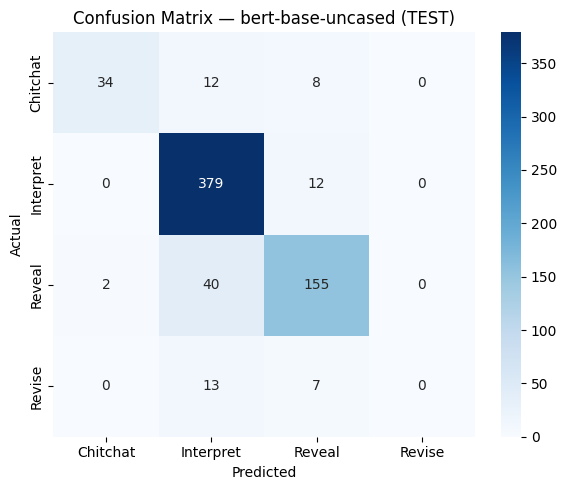


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,40
1,Revise,Interpret,13
2,Chitchat,Interpret,12
3,Interpret,Reveal,12
4,Chitchat,Reveal,8
5,Revise,Reveal,7
6,Reveal,Chitchat,2



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret


In [18]:
bert_trainer = run_model("bert-base-uncased", num_epochs=5)

## MiniLM


  MODEL: microsoft/MiniLM-L12-H384-uncased


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

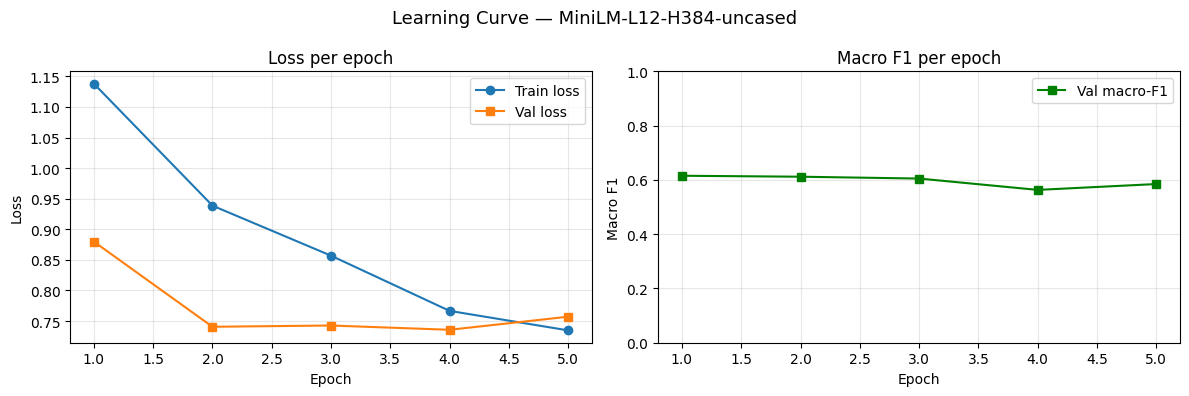

Saved: minilm-l12-h384-uncased_learning_curve.png



=== MiniLM-L12-H384-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.833     0.426     0.564       176
   Interpret      0.832     0.886     0.858      1130
      Reveal      0.771     0.826     0.798       673
      Revise      0.000     0.000     0.000        35

    accuracy                          0.810      2014
   macro avg      0.609     0.535     0.555      2014
weighted avg      0.797     0.810     0.797      2014


=== MiniLM-L12-H384-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              75              72           29            0
true_Interpret              3            1001          126            0
true_Reveal                12             105          556            0
true_Revise                 0              25           10            0


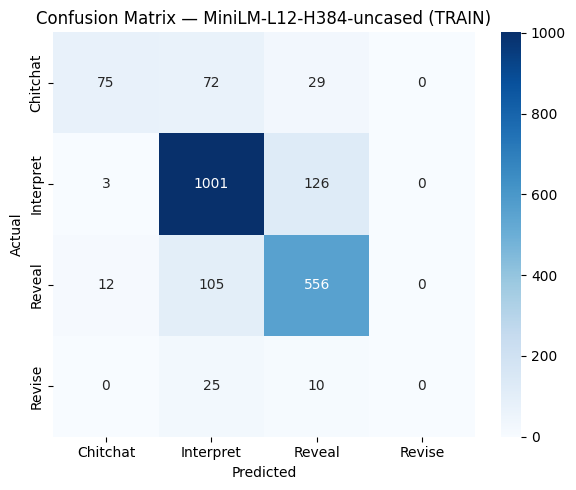


=== MiniLM-L12-H384-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.958     0.605     0.742        38
   Interpret      0.861     0.894     0.877       292
      Reveal      0.801     0.876     0.837       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.845       503
   macro avg      0.655     0.594     0.614       503
weighted avg      0.829     0.845     0.833       503


=== MiniLM-L12-H384-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              23              12            3            0
true_Interpret              1             261           30            0
true_Reveal                 0              20          141            0
true_Revise                 0              10            2            0


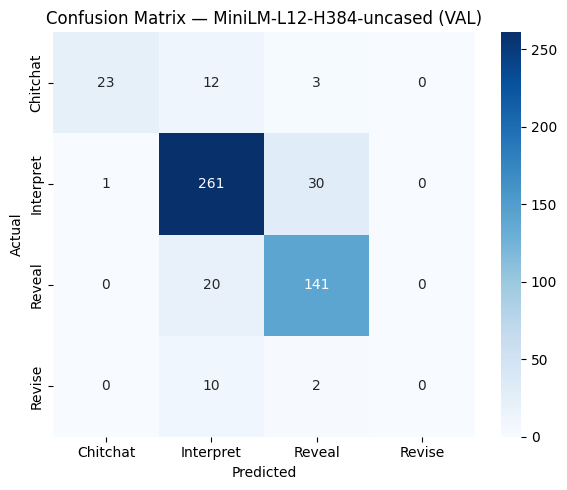


=== MiniLM-L12-H384-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,30
1,Reveal,Interpret,20
2,Chitchat,Interpret,12
3,Revise,Interpret,10
4,Chitchat,Reveal,3
5,Revise,Reveal,2
6,Interpret,Chitchat,1



=== MiniLM-L12-H384-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
2,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
18,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
31,USER: hello!\nSYSTEM: hi\nUSER: I wanna a phot...,Interpret,Reveal
34,USER: I want to phone holder for my iphone 16 ...,Interpret,Reveal
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret



=== MiniLM-L12-H384-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.944     0.630     0.756        54
   Interpret      0.859     0.905     0.882       391
      Reveal      0.762     0.827     0.793       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.832       662
   macro avg      0.641     0.591     0.608       662
weighted avg      0.811     0.832     0.818       662


=== MiniLM-L12-H384-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              34              12            8            0
true_Interpret              0             354           37            0
true_Reveal                 2              32          163            0
true_Revise                 0              14            6            0


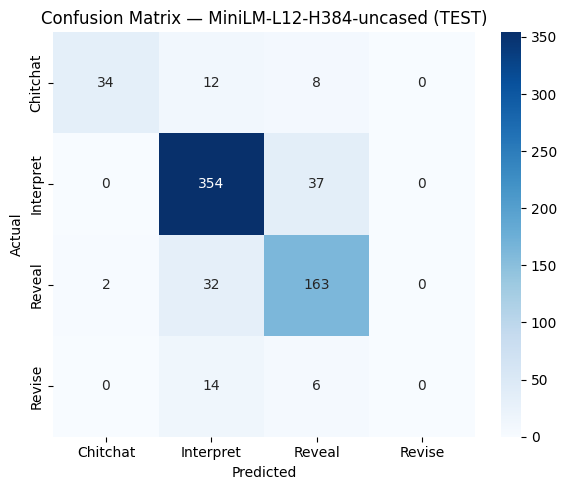


=== MiniLM-L12-H384-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,37
1,Reveal,Interpret,32
2,Revise,Interpret,14
3,Chitchat,Interpret,12
4,Chitchat,Reveal,8
5,Revise,Reveal,6
6,Reveal,Chitchat,2



=== MiniLM-L12-H384-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Reveal


In [19]:
minilm_trainer = run_model("microsoft/MiniLM-L12-H384-uncased", num_epochs=5)

## DeBERTa-v3-base

> **Note:** Run the cell below before this model if sentencepiece is not installed.
> ```
> !pip install sentencepiece -q
> ```

In [20]:
#!pip install sentencepiece -q


In [21]:
#deberta_trainer = run_model("microsoft/deberta-v3-base", num_epochs=5)

**Inference check**

In [22]:
import time
import pandas as pd

runtime_rows = []

models_to_check = [
    ("BERT Base", bert_trainer),
    ("DistilBERT", distilbert_trainer),
    ("RoBERTa", roberta_trainer),
    ("MiniLM", minilm_trainer),
]

for model_name, trainer in models_to_check:

    start = time.time()

    pred_out = trainer.predict(
        make_hf_datasets(
            trainer.tokenizer if hasattr(trainer, "tokenizer") else AutoTokenizer.from_pretrained("bert-base-uncased"),
            X_train, y_train_ids,
            X_val, y_val_ids,
            X_test, y_test_ids
        )[2]
    )

    end = time.time()

    total_time = end - start
    avg_time = total_time / len(X_test)

    runtime_rows.append({
        "model": model_name,
        "test_samples": len(X_test),
        "total_inference_sec": round(total_time, 3),
        "avg_inference_per_sample_sec": round(avg_time, 5)
    })

runtime_df = pd.DataFrame(runtime_rows)

display(runtime_df)

runtime_df.to_csv(
    "/content/drive/MyDrive/thesis_final_results_4class_noaugment/model_inference_runtime.csv",
    index=False
)

,model,test_samples,total_inference_sec,avg_inference_per_sample_sec
0,BERT Base,662,3.306,0.00499
1,DistilBERT,662,2.790,0.00421
2,RoBERTa,662,3.521,0.00532
3,MiniLM,662,3.414,0.00516
